# From a frozen model to an honest operating check

## Goal
Export a fitted pipeline, score a new batch without refitting, reject unavailable inputs,
and wait for delayed outcomes before computing error. The worked example has **two
pending labels at hour 0**, then **MAE 6 kWh/day at hour 48**. These outcomes are
fabricated for practice, not external evidence of usefulness.

**Pause before running:** if an input moves outside its training range but no outcome
has arrived, what can you conclude about accuracy? Write your answer first.

## Setup
Extract the whole kit; use its pinned Python 3.12 environment. The portable `serve.py`
scorer itself uses only the standard library. Its JSON format supports the browser's
linear/logistic fit and one-split tree; it does not serialize every sklearn estimator,
calibration wrapper, or imputer. Preserve those full pipelines separately when needed.
The reference is [scikit-learn's model-persistence guide](https://scikit-learn.org/stable/model_persistence.html).

In [1]:
from copy import deepcopy
from pathlib import Path
import json, subprocess, sys, tempfile
import matplotlib.pyplot as plt
from workshop import make_dataset, partition, manual_fit, manual_predict, metrics
from serve import artifact_from_manual, score_batch, monitor_batch
plt.rcParams.update({'figure.figsize': (8.5, 4.2), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

## Steps
### 1. Freeze a declared fit before final evidence
This reuses the energy project and its original synthetic generator. Scaling uses only
training observations. No final result chooses the algorithm or hyperparameters below.
The copy fixes the fitted parameters; copying alone cannot prove that a human followed
the evaluation protocol. Use the earlier project for the complete prediction contract.

In [2]:
rows = make_dataset('energy', 42)
training = partition(rows, 'train')
final_rows = partition(rows, 'test')
frozen = deepcopy(manual_fit(training, penalty=.1))
print('Declared final evidence:', metrics(
    [r['y'] for r in final_rows], manual_predict(frozen, final_rows)))
artifact = artifact_from_manual('energy', frozen, training)
print('Features:', [f['key'] for f in artifact['features']])
print('Window:', artifact['horizonHours'], 'elapsed hours')

Declared final evidence: {'mae': 2.9760358029573633, 'rmse': 3.45133012325074, 'bias': 0.24115891115770935}
Features: ['temperature', 'planned_production']
Window: 24 elapsed hours


### 2. Score hypothetical inputs without seeing outcomes
Features map by name, not incoming dictionary order. Each value has its publication
time. Both examples are known at hour 0. **Before running:** does a forecast need its
future target to produce a prediction? What must travel with the coefficients?

In [3]:
batch = [dict(id=f'batch-{i+1}', predictionTime=0, features={
    f['key']: dict(value=f['min']+fraction*(f['max']-f['min']), availableAt=0)
    for f in artifact['features']}) for i, fraction in enumerate((.4, .6))]
scored = score_batch(artifact, batch)
print(json.dumps(scored['rows'], indent=2))
assert 'actual' not in batch[0]

[
  {
    "id": "batch-1",
    "predictionTime": 0,
    "prediction": 80.42012293264236,
    "alert": null,
    "outsideTrainingRange": []
  },
  {
    "id": "batch-2",
    "predictionTime": 0,
    "prediction": 101.99694273081965,
    "alert": null,
    "outsideTrainingRange": []
  }
]


### 3. Diagnose a plausible mistake
Someone says, “the measurement describes the right day, so we can use it.” But the
report was published an hour after the decision. Event time and availability time
answer different questions. The scorer rejects the whole batch. Correct metadata
alone does not repair a real late source: obtain a value available at cutoff or change
the decision contract and reevaluate.

In [4]:
broken = deepcopy(batch)
broken[0]['features']['temperature']['availableAt'] = 1
try:
    score_batch(artifact, broken)
except ValueError as error:
    print('Rejected:', error)
else:
    raise AssertionError('A late input was incorrectly accepted')
repaired = deepcopy(batch)  # actual known-at-cutoff practice values
assert len(score_batch(artifact, repaired)['rows']) == 2

Rejected: batch-1: temperature arrives after the prediction cutoff.


### 4. Wait for mature outcomes
Invent two outcomes only for this exercise: actual = prediction + 4, then prediction − 8.
Both reports arrive at hour 48: a 24-hour outcome window plus 24 hours of reporting delay.
Thus the residuals are −4 and +8, MAE = (4+8)/2 = **6 kWh/day**, and signed bias = **+2**.
**Pause:** what should the metric show at hour 24? Do not treat pending labels as zeros.

In [5]:
labels = [dict(id=r['id'], actual=r['prediction']+(4 if i == 0 else -8),
               availableAt=48) for i, r in enumerate(scored['rows'])]
early = monitor_batch(scored, labels, 24)
later = monitor_batch(scored, labels, 48)
print('Hour 24:', early)
print('Hour 48:', later)
assert early['metrics'] is None and early['pending'] == 2
assert later['metrics']['mae'] == 6 and later['metrics']['bias'] == 2

Hour 24: {'issued': 2, 'labeled': 0, 'pending': 2, 'outsideTrainingRange': 0, 'metrics': None}
Hour 48: {'issued': 2, 'labeled': 2, 'pending': 0, 'outsideTrainingRange': 0, 'metrics': {'mae': 6.0, 'rmse': 6.324555320336759, 'bias': 2.0, 'r2': -0.7445256182946594}}


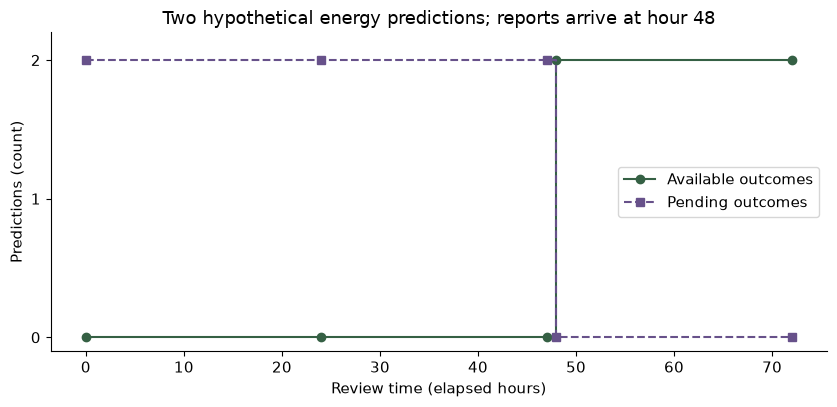

In [6]:
hours = [0, 24, 47, 48, 72]
reports = [monitor_batch(scored, labels, hour) for hour in hours]
fig, ax = plt.subplots()
ax.step(hours, [r['labeled'] for r in reports], where='post', marker='o',
        color='#356044', label='Available outcomes')
ax.step(hours, [r['pending'] for r in reports], where='post', linestyle='--',
        marker='s', color='#67518a', label='Pending outcomes')
ax.set(xlabel='Review time (elapsed hours)', ylabel='Predictions (count)',
       title='Two hypothetical energy predictions; reports arrive at hour 48',
       yticks=[0, 1, 2], ylim=(-.1, 2.2))
ax.legend(); fig.tight_layout(); plt.show()

### 5. Separate input warnings from performance evidence
A value outside the training range flags extrapolation. A value within all marginal
ranges may still be an unfamiliar combination; this check is deliberately simple.
Without mature labels we cannot determine error. Selectively missing outcomes may
also bias the measured error after some labels arrive. Drift alone does not justify
automatic retraining or certify that performance is unchanged.

In [7]:
changed = deepcopy(batch)
feature = artifact['features'][0]
changed[0]['features'][feature['key']]['value'] = feature['max']+10
warning = monitor_batch(score_batch(artifact, changed), [], 0)
print(warning)
assert warning['outsideTrainingRange'] == 1 and warning['metrics'] is None

{'issued': 2, 'labeled': 0, 'pending': 2, 'outsideTrainingRange': 1, 'metrics': None}


### 6. Run the same handoff as local files
In the app, step 7 downloads the exact fitted artifact and batch; use them in place of
these temporary examples. Keep input data, model, labels, software/data versions, and
the decision memo together. The scorer does not train or make a rollout decision.

In [8]:
with tempfile.TemporaryDirectory() as directory:
    folder = Path(directory)
    for name, value in [('model', artifact), ('batch', batch), ('labels', labels)]:
        (folder/f'{name}.json').write_text(json.dumps(value))
    script = str(Path('serve.py').resolve())
    subprocess.run([sys.executable, script, 'score', str(folder/'model.json'),
                    str(folder/'batch.json'), str(folder/'predictions.json')], check=True)
    subprocess.run([sys.executable, script, 'monitor', str(folder/'predictions.json'),
                    str(folder/'labels.json'), '48', str(folder/'report.json')], check=True)
    report = json.loads((folder/'report.json').read_text())
    assert report['metrics']['mae'] == 6
    print('File roundtrip MAE:', report['metrics']['mae'])

Wrote /var/folders/pq/cm3rh72d5qgfg_4112x8l_nh0000gn/T/tmpyo3yinfh/predictions.json
Wrote /var/folders/pq/cm3rh72d5qgfg_4112x8l_nh0000gn/T/tmpyo3yinfh/report.json
File roundtrip MAE: 6.0


## Checks
Strict feature names/dimensions, finite values, duplicate IDs, publication cutoffs,
binary domains, label windows, label availability, and training transforms are checked.
This does not authenticate source timestamps, establish representativeness, or provide
monitoring alerts for a real system. The JSON artifact is unsigned. The model format
intentionally rejects missing features rather than fitting or inventing an imputer.

## Next Steps
One independent exercise: change the second report's arrival to hour 60. Before
running, calculate labeled/pending counts, MAE, and bias at hours 48 and 60. Explain
why the first available outcome may not represent all future predictions. Attempt it
before opening `solutions/HANDOFF.md`. Then write the owner, fallback, and conditions
for investigation, rollback, and a newly evaluated retraining experiment.